---

<br>

# MODULE 3: PRE-MODELLING DATA PREPARATION & EDA

<br>

---

# 🔎 Pre-Modeling Data Prep & EDA

Before applying any regression algorithm, we need to prepare the data and get to know it well. This stage covers the **data preparation** and **Exploratory Data Analysis (EDA)** steps required before modeling — the techniques we use to explore the target, the features, and the relationships among them.

**What this section covers:**
- EDA for Regression
- Exploring the Target
- Exploring the Features
- Linear Relationships
- Exploring Relationships
- Preparing for Modeling

**Goals for this section:**
- Visualize and explore the target and the features
- Quantify the strength of linear relationships
- Identify relationships between the target and features — and between features themselves
- Review the data prep steps required before modeling

<br><br>

---

## EDA for Regression

**Exploratory Data Analysis (EDA)** is the process of exploring and visualizing data to uncover useful patterns and insights that help inform the modeling process.

In a regression context, EDA serves two main purposes:

- It lets you **identify and understand the most promising features** for your model — the ones most likely to carry signal about the target.
- It helps you **surface potential problems** with the features or the target (*skew, outliers, missing values, odd distributions*) that must be addressed before modeling.

When performing **EDA for regression**, four things are especially important to explore:

1. **The target variable** — its center, spread, and shape.
2. **The features** — each one, individually.
3. **Feature–target relationships** — does each feature actually relate to what we're predicting?
4. **Feature–feature relationships** — do features move together with one another? (*This matters later for issues such as `multicollinearity`*)

> 💡 **Note:** Data cleaning technically comes *before* EDA in the workflow, but in practice EDA almost always **reveals additional cleaning steps** still needed before modeling. The two stages feed back into each other.

<br><br>

---

## Exploring the Target

Exploring the **target variable** lets you understand three things: **where most of the values lie** (center), **how spread out they are** (spread), and **what shape — or distribution — they have**.

Two charts are especially useful for this:

- **Histograms** — show the full shape of the distribution (where values cluster, whether it is symmetric or skewed).
- **Boxplots** — summarize center, spread, and outliers in a compact form.

The **`seaborn`** library is ideal for these charts:

```python
import seaborn as sns

# Histogram of the target
sns.histplot(diamonds["price"]);
```

```python
# Boxplot of the target
sns.boxplot(x=diamonds["price"])
sns.despine()   # removes the top & right borders for a cleaner look
```

<br><br>

---

### Reading the diamonds `price` target

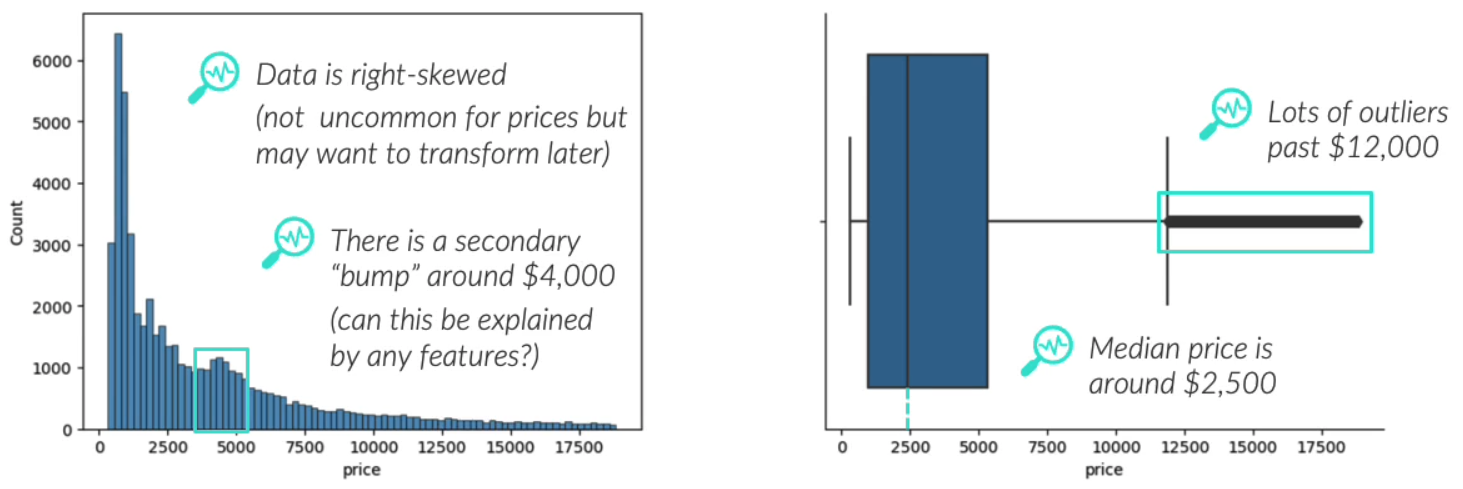

Looking at the histogram and boxplot of diamond prices, several insights stand out:

- **The distribution is right-skewed** — a long tail toward high prices. This is not uncommon for prices, but we may want to **transform** the target later (e.g., a log transform) to make it easier to model.
- There is a **secondary "bump" around \$4,000** in the histogram — worth asking whether some feature can explain it.
- The boxplot shows **many outliers past \$12,000** — extreme, but potentially real high-value diamonds.
- The **median price is around \$2,500**, well below the upper tail, which is consistent with the right skew.

> Each of these observations is a *lead*: EDA doesn't just describe the data, it raises questions ("can a feature explain this bump?") and flags decisions ("should we transform the target?") that shape the modeling to come.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
insurance = pd.read_csv('../datasets/insurance.csv')
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Let's check if there is consistency between the datatype of the dataset and value each column has
insurance.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [6]:
# Now it's time to see some stats...
insurance.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


<br><br>

---

Now we'll create a couple of plots in order to know better our `target`

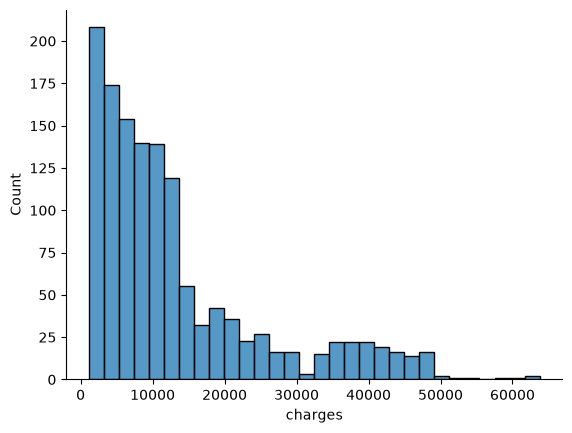

In [7]:
sns.histplot(x=insurance.charges)
sns.despine()

- The upper plot has is right-skewed.
- It has a secondary bump around 32000 USD.
   - There's like some category or maybe some step in a numeric predictor that's causing a bump.


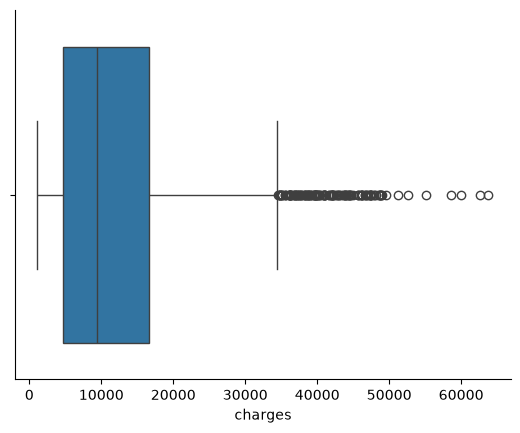

In [9]:
sns.boxplot(x=insurance.charges)
sns.despine()

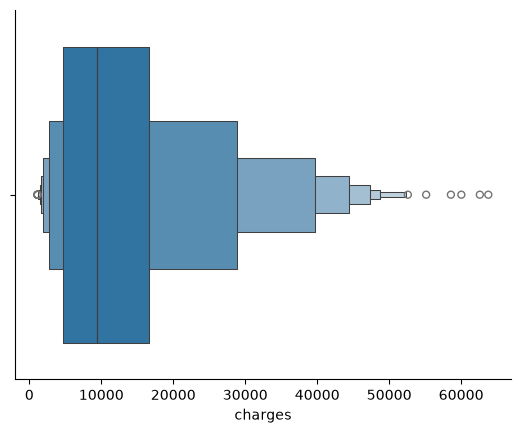

In [10]:
# the 
sns.boxenplot(x=insurance.charges)
sns.despine()

> `boxenplot`: This style of plot was originally named a “letter value” plot because it shows a large number of quantiles that are defined as “letter values”. It is similar to a box plot in plotting a nonparametric representation of a distribution in which all features correspond to actual observations. By plotting more quantiles, it provides more information about the shape of the distribution, particularly in the tails.

<br><br>